# 01 · Routing, duration & continuity, currency conversions
Feature groups: **Payment Routing**, **Duration & Continuity**, **Currency Conversions**.

Each section follows the same loop: **hypothesis → test on all 10M rows → confounder check → rule with size and scope → status.**

In [1]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## A. Payment routing
### H-A1  `PARTICIPANT_COUNT` is the number of banks in `BIC8_PATH`; `Direct` means exactly 2 banks

In [2]:
pd.concat([
    rule_check('PARTICIPANT_COUNT = BICs in path', 'PARTICIPANT_COUNT = N_PATH_BICS'),
    rule_check('Direct  <=>  2 participants', "(TRANSACTION_TYPE_CODE='Direct') = (PARTICIPANT_COUNT=2)"),
])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,PARTICIPANT_COUNT = BICs in path,10400000,10400000.0,100.0,0.0
0,Direct <=> 2 participants,10400000,10400000.0,100.0,0.0


### H-A2  The number of intermediaries follows a geometric law (each extra bank is added with a constant probability)

In [3]:
k = q('SELECT PARTICIPANT_COUNT k, count(*) n FROM f GROUP BY 1 ORDER BY 1')
k['share'] = k.n / k.n.sum()
k['ratio_to_previous'] = k.n / k.n.shift(1)
export(k, 'routing_participant_count'); k.head(12)

,k,n,share,ratio_to_previous
0,2,6575823,0.632291,NaN
1,3,2417505,0.232452,0.367635
2,4,889503,0.085529,0.367943
3,5,326729,0.031416,0.367316
4,6,120386,0.011576,0.368458
5,7,44391,0.004268,0.368739
6,8,16086,0.001547,0.362371
7,9,5988,0.000576,0.372249
8,10,2306,0.000222,0.385104
9,11,801,0.000077,0.347355


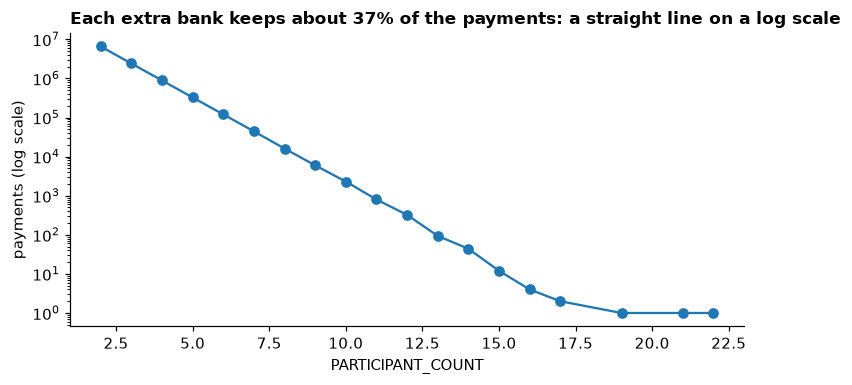

In [4]:
fig, ax = plt.subplots(figsize=(7,3.6))
ax.semilogy(k.k, k.n, 'o-'); ax.set_xlabel('PARTICIPANT_COUNT'); ax.set_ylabel('payments (log scale)')
r = k.ratio_to_previous[1:7].mean()
ax.set_title(f'Each extra bank keeps about {r:.0%} of the payments: a straight line on a log scale')
savefig('A2_participant_count_geometric')

A straight line on a log axis = constant ratio = geometric distribution. Confounder check: is the ratio the same for every customer flow and for domestic vs cross-border?

In [5]:
q('''SELECT FLOW, IS_DOMESTIC, count(*) n,
            avg((PARTICIPANT_COUNT>=3)::int) AS p_ge3,
            sum((PARTICIPANT_COUNT>=4)::int)/sum((PARTICIPANT_COUNT>=3)::int) AS p_ge4_given_ge3,
            sum((PARTICIPANT_COUNT>=5)::int)/sum((PARTICIPANT_COUNT>=4)::int) AS p_ge5_given_ge4
     FROM f GROUP BY ALL ORDER BY 2,1''')

,FLOW,IS_DOMESTIC,n,p_ge3,p_ge4_given_ge3,p_ge5_given_ge4
0,B2B,False,2194967,0.367949,0.368381,0.366116
1,B2C,False,5413180,0.367692,0.367675,0.367207
2,C2B,False,591279,0.368219,0.368570,0.367101
3,C2C,False,1461447,0.367257,0.367176,0.370315
4,B2B,True,166909,0.365924,0.370047,0.372240
5,B2C,True,413534,0.368149,0.367645,0.369906
6,C2B,True,43972,0.367325,0.365094,0.369849
7,C2C,True,114712,0.368253,0.368203,0.371673


### H-A3  Among routed payments (3+ banks) a fixed share is `Covered`, independent of path length

In [6]:
cov = q('''SELECT PARTICIPANT_COUNT k, count(*) n, avg((TRANSACTION_TYPE_CODE='Covered')::int) AS share_covered
             FROM f WHERE PARTICIPANT_COUNT BETWEEN 3 AND 9 GROUP BY 1 ORDER BY 1'''); export(cov,'routing_covered_share'); cov

,k,n,share_covered
0,3,2417505,0.113175
1,4,889503,0.112968
2,5,326729,0.113384
3,6,120386,0.113011
4,7,44391,0.112928
5,8,16086,0.114820
6,9,5988,0.119071


In [7]:
q('''SELECT FLOW, IS_DOMESTIC, count(*) n, avg((TRANSACTION_TYPE_CODE='Covered')::int) AS share_covered,
            avg(LOG10_USD) FILTER (TRANSACTION_TYPE_CODE='Covered') AS mean_log_amt_covered,
            avg(LOG10_USD) FILTER (TRANSACTION_TYPE_CODE='Indirect') AS mean_log_amt_indirect
     FROM f WHERE PARTICIPANT_COUNT>=3 GROUP BY ALL ORDER BY 2,1''')

,FLOW,IS_DOMESTIC,n,share_covered,mean_log_amt_covered,mean_log_amt_indirect
0,B2B,False,807637,0.104860,4.390742,4.319231
1,B2C,False,1990381,0.107722,3.516625,3.449507
2,C2B,False,217720,0.105548,3.518625,3.465294
3,C2C,False,536726,0.104947,2.671106,2.609961
4,B2B,True,61076,0.196084,4.524053,4.558076
5,B2C,True,152242,0.205797,3.659601,3.682546
6,C2B,True,16152,0.182826,3.663982,3.656561
7,C2C,True,42243,0.190375,2.777166,2.824105


### H-A4  Endpoint mismatch: when the path does not start at `ORDERING_BIC8`, is it another bank of the same country?

In [8]:
q('''SELECT PATH_FIRST_IS_ORD, PATH_LAST_IS_BEN, count(*) n,
            avg((substr(string_split(BIC8_PATH,';')[1],5,2)=ORD_COUNTRY)::int)  AS first_same_country_as_ord,
            avg((substr(string_split(BIC8_PATH,';')[-1],5,2)=BEN_COUNTRY)::int) AS last_same_country_as_ben,
            avg((substr(string_split(BIC8_PATH,';')[1],1,4)=substr(ORDERING_BIC8,1,4))::int) AS first_same_4digit_prefix
     FROM f GROUP BY ALL ORDER BY n DESC''')

,PATH_FIRST_IS_ORD,PATH_LAST_IS_BEN,n,first_same_country_as_ord,last_same_country_as_ben,first_same_4digit_prefix
0,True,True,9388171,1.000000,1.000000,1.000000
1,True,False,493622,1.000000,0.058670,1.000000
2,False,True,492578,0.048240,1.000000,0.004381
3,False,False,25629,0.049319,0.058293,0.004916


## B. Duration & continuity
### H-B1  `CONTINUITY_QFLAG='N'` is exactly "path contains `...`", and each link is hidden independently with probability 5%
If every one of the k−1 links is hidden independently with probability p, then P(gap) = 1 − (1−p)^(k−1).

In [9]:
gap = q('''SELECT PARTICIPANT_COUNT k, count(*) n, avg(HAS_GAP::int) AS observed_p_gap
             FROM f GROUP BY 1 HAVING count(*) >= 300 ORDER BY 1''')
gap['model_p_5pct_per_link'] = 1 - 0.95 ** (gap.k - 1)
gap['implied_p_per_link'] = 1 - (1 - gap.observed_p_gap) ** (1 / (gap.k - 1))
export(gap, 'continuity_gap_model'); gap

,k,n,observed_p_gap,model_p_5pct_per_link,implied_p_per_link
0,2,6575823,0.049858,0.050000,0.049858
1,3,2417505,0.097412,0.097500,0.049954
2,4,889503,0.142442,0.142625,0.049933
3,5,326729,0.184783,0.185494,0.049793
4,6,120386,0.225616,0.226219,0.049852
5,7,44391,0.268928,0.264908,0.050868
6,8,16086,0.308280,0.301663,0.051291
7,9,5988,0.330494,0.336580,0.048915
8,10,2306,0.382047,0.369751,0.052077
9,11,801,0.419476,0.401263,0.052930


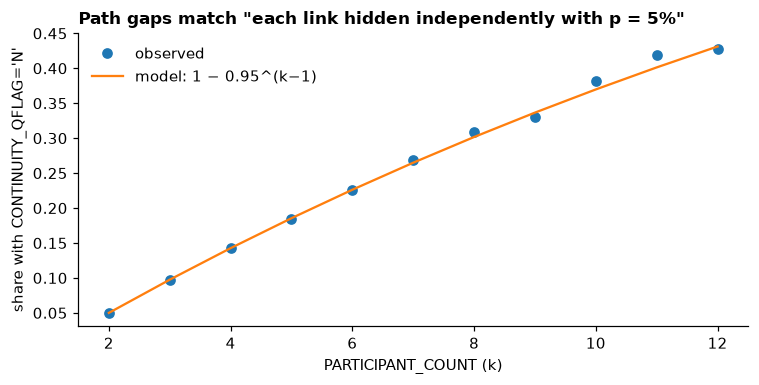

In [10]:
fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(gap.k, gap.observed_p_gap, 'o', label='observed'); ax.plot(gap.k, gap.model_p_5pct_per_link, '-', label='model: 1 − 0.95^(k−1)')
ax.set_xlabel('PARTICIPANT_COUNT (k)'); ax.set_ylabel("share with CONTINUITY_QFLAG='N'"); ax.legend(frameon=False)
ax.set_title('Path gaps match "each link hidden independently with p = 5%"'); savefig('B1_gap_model')

In [11]:
# where does the '...' sit, and how many gaps per path?
q('''SELECT PARTICIPANT_COUNT k, len(string_split(BIC8_PATH,';')) - N_PATH_BICS AS n_gaps, count(*) n
     FROM f WHERE PARTICIPANT_COUNT<=4 GROUP BY ALL ORDER BY 1,2''')

,k,n_gaps,n
0,2,0,6247963
1,2,1,311344
2,2,2,15711
3,2,3,770
4,2,4,31
5,2,5,4
6,3,0,2182011
7,3,1,218101
8,3,2,16279
9,3,3,1042


### H-B2  `TOTAL_DURATION` is a sum of per-hop delays: it grows with the number of banks, not with amount or flow

In [12]:
dur = q('''SELECT PARTICIPANT_COUNT k, count(*) n, min(TOTAL_DURATION) mn,
                  quantile_cont(TOTAL_DURATION,0.25) q25, median(TOTAL_DURATION) med,
                  quantile_cont(TOTAL_DURATION,0.75) q75, avg(TOTAL_DURATION) mean, stddev(TOTAL_DURATION) sd
           FROM f WHERE PARTICIPANT_COUNT<=9 GROUP BY 1 ORDER BY 1'''); export(dur,'duration_by_participants'); dur

,k,n,mn,q25,med,q75,mean,sd
0,2,6575823,2,21.00,39.0,877.00,663.298113,1133.361253
1,3,2417505,3,32.00,126.0,1294.00,840.703667,1266.252168
2,4,889503,4,47.00,418.0,1640.50,1041.699048,1393.888364
3,5,326729,6,67.00,590.0,1953.00,1241.668787,1509.918785
4,6,120386,7,133.00,795.0,2249.00,1436.318368,1613.371585
5,7,44391,11,292.00,1033.0,2548.50,1649.050731,1730.585819
6,8,16086,15,408.25,1236.5,2810.00,1837.039724,1833.148062
7,9,5988,25,515.00,1475.5,3091.25,2022.830661,1918.394244


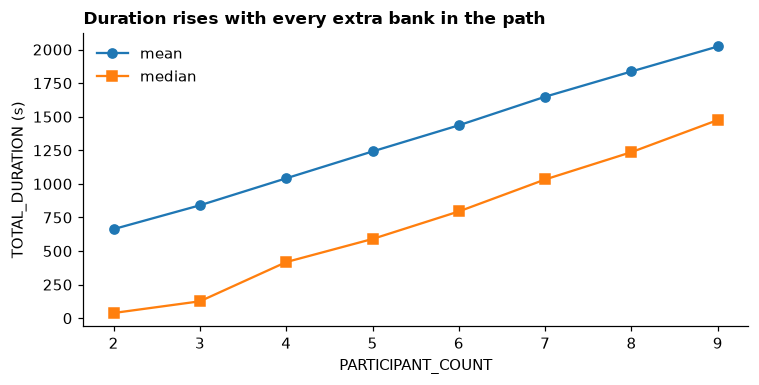

In [13]:
fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(dur.k, dur['mean'], 'o-', label='mean'); ax.plot(dur.k, dur.med, 's-', label='median')
ax.set_xlabel('PARTICIPANT_COUNT'); ax.set_ylabel('TOTAL_DURATION (s)'); ax.legend(frameon=False)
ax.set_title('Duration rises with every extra bank in the path'); savefig('B2_duration_by_participants')

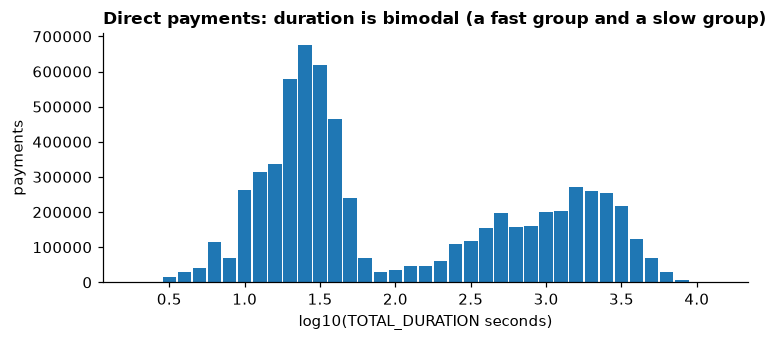

In [14]:
# shape of the duration distribution for the simplest case (Direct): is it a mixture?
h = q('''SELECT round(log10(TOTAL_DURATION),1) lg, count(*) n FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(7,3.2)); ax.bar(h.lg, h.n, width=0.09)
ax.set_xlabel('log10(TOTAL_DURATION seconds)'); ax.set_ylabel('payments')
ax.set_title('Direct payments: duration is bimodal (a fast group and a slow group)'); savefig('B2_duration_direct_bimodal')

In [15]:
# what separates the fast and the slow group? candidate drivers one at a time
for col in ['CURRENCY_CONVERSION_COUNT','IS_DOMESTIC','FLOW','IS_WEEKEND','HAS_GAP','PATH_FIRST_IS_ORD']:
    display(q(f'''SELECT {col}, count(*) n, avg((TOTAL_DURATION>300)::int) AS share_slow, median(TOTAL_DURATION) med
                  FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1'''))

,CURRENCY_CONVERSION_COUNT,n,share_slow,med
0,0,1031167,0.394048,45.0
1,1,5544656,0.357122,38.0


,IS_DOMESTIC,n,share_slow,med
0,False,6108409,0.358137,39.0
1,True,467414,0.425327,56.0


,FLOW,n,share_slow,med
0,B2B,1493163,0.360157,39.0
1,B2C,3684091,0.360839,39.0
2,C2B,401379,0.371836,40.0
3,C2C,997190,0.371109,39.0


,IS_WEEKEND,n,share_slow,med
0,False,5840175,0.363064,39.0
1,True,735648,0.361714,39.0


,HAS_GAP,n,share_slow,med
0,False,6247963,0.362862,39.0
1,True,327860,0.363872,39.0


,PATH_FIRST_IS_ORD,n,share_slow,med
0,False,327528,0.363383,39.0
1,True,6248295,0.362888,39.0


In [16]:
q('''SELECT HOUR_UTC, count(*) n, avg((TOTAL_DURATION>300)::int) AS share_slow FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1''').T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
HOUR_UTC,0.000000,1.000000,2.000000,3.000000,4.000000,5.000000,6.000000,7.00000,8.000000,9.000000,10.000000,11.000000,12.000000,13.000000,14.00000,15.000000,16.000000,17.000000,18.000000,19.000000,20.00000,21.000000,22.000000,23.000000
n,203021.000000,170001.000000,153181.000000,143410.000000,148307.000000,203017.000000,320921.000000,330316.00000,307102.000000,307325.000000,290759.000000,284107.000000,365088.000000,332321.000000,329543.00000,385345.000000,375838.000000,361095.000000,336241.000000,277417.000000,241633.00000,239002.000000,219906.000000,250927.000000
share_slow,0.356357,0.359851,0.365137,0.367457,0.371486,0.363881,0.362691,0.36657,0.364745,0.366068,0.368931,0.370241,0.361247,0.363585,0.36276,0.358814,0.360839,0.363262,0.362984,0.364253,0.36183,0.358407,0.357385,0.353808


In [17]:
q('''SELECT round(LOG10_USD) AS log10_amount, count(*) n, avg((TOTAL_DURATION>300)::int) AS share_slow, median(TOTAL_DURATION) med
     FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1''')

,log10_amount,n,share_slow,med
0,-2.0,364,0.439560,46.0
1,-1.0,1816,0.471366,131.5
2,0.0,26588,0.423838,45.0
3,1.0,211040,0.404753,43.0
4,2.0,904990,0.382540,41.0
5,3.0,2002114,0.366588,39.0
6,4.0,2128748,0.354479,39.0
7,5.0,1047027,0.350016,38.0
8,6.0,230952,0.346124,38.0
9,7.0,21294,0.342491,38.0


## C. Currency conversions
### H-C1  A conversion can happen on each link; `CURRENCY_CONVERSION_COUNT` ≤ k−1

In [18]:
rule_check('FX count <= PARTICIPANT_COUNT - 1', 'CURRENCY_CONVERSION_COUNT <= PARTICIPANT_COUNT - 1')

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,FX count <= PARTICIPANT_COUNT - 1,10400000,10400000.0,100.0,0.0


### H-C2  A link converts when it crosses a country border (domestic links do not convert)
Simplest clean test: Direct payments with a fully visible path (one link only).

In [19]:
fx1 = q('''SELECT N_PATH_COUNTRIES = 1 AS link_within_one_country, CURRENCY_CONVERSION_COUNT fx, count(*) n
             FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP GROUP BY ALL ORDER BY 1,2''')
fx1['share_within_group'] = fx1.n / fx1.groupby('link_within_one_country').n.transform('sum'); export(fx1,'fx_direct_border'); fx1

,link_within_one_country,fx,n,share_within_group
0,False,0,524955,0.090614
1,False,1,5268331,0.909386
2,True,0,454677,1.000000


Same-country links never convert (0 exceptions). Cross-border links convert about 91% of the time. **What explains the 9% that do not?** Candidate: the two countries share a currency, or the payment currency is the home currency on both sides.

In [20]:
# country pairs that (almost) never convert although they cross a border
pairs = q('''SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2,
                    count(*) n, avg(CURRENCY_CONVERSION_COUNT) p_convert
             FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP AND N_PATH_COUNTRIES=2 GROUP BY ALL HAVING count(*)>=500''')
print('pairs:', len(pairs)); print(pairs.p_convert.round(1).value_counts().sort_index())
pairs.sort_values('p_convert').head(25)

pairs: 1647
p_convert
0.0     153
1.0    1494
Name: count, dtype: int64


,c1,c2,n,p_convert
1642,FR,LT,593,0.0
23,NL,FI,2757,0.0
1603,IT,LT,597,0.0
1586,LT,IT,599,0.0
1588,US,EC,773,0.0
1554,DE,CY,1502,0.0
1547,AT,FI,1012,0.0
1536,FI,AT,868,0.0
1479,IT,MT,1055,0.0
1432,MC,LU,1033,0.0


In [21]:
# data-driven currency zones: countries linked by never-converting pairs
import networkx as nx
G = nx.Graph(); G.add_edges_from(pairs[pairs.p_convert < 0.02][['c1','c2']].itertuples(index=False))
zones = sorted([sorted(c) for c in nx.connected_components(G)], key=len, reverse=True)
for z in zones: print(len(z), z)

19 ['AD', 'AT', 'BE', 'CY', 'DE', 'ES', 'FI', 'FR', 'IE', 'IT', 'LT', 'LU', 'LV', 'MC', 'MQ', 'MT', 'NL', 'PT', 'SI']
5 ['BQ', 'EC', 'PR', 'US', 'VG']
3 ['GB', 'IM', 'JE']
2 ['CH', 'LI']


In [22]:
# test the zone rule on ALL direct visible payments
zone_of = {c: i for i, z in enumerate(zones) for c in z}
zdf = pd.DataFrame({'country': list(zone_of), 'zone': list(zone_of.values())})
from utils import con; con.register('zdf', zdf)
q('''WITH d AS (SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2, CURRENCY_CONVERSION_COUNT fx
               FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP)
     SELECT coalesce('Z'||z1.zone::varchar, c1) = coalesce('Z'||z2.zone::varchar, c2) AS same_currency_area, fx, count(*) n
     FROM d LEFT JOIN zdf z1 ON z1.country=c1 LEFT JOIN zdf z2 ON z2.country=c2 GROUP BY ALL ORDER BY 1,2''')

,same_currency_area,fx,n
0,False,0,15558
1,False,1,5268331
2,True,0,964074


### H-C3  For longer paths the FX count is the number of links that cross a currency border

In [23]:
q('''WITH t AS (SELECT ROW_ID, CURRENCY_CONVERSION_COUNT fx, list_transform(string_split(BIC8_PATH,';'), lambda x: substr(x,5,2)) cs
               FROM f WHERE NOT HAS_GAP AND PARTICIPANT_COUNT BETWEEN 3 AND 6),
          u AS (SELECT ROW_ID, fx, unnest(cs) c, generate_subscripts(cs,1) i FROM t),
          z AS (SELECT u.*, coalesce('Z'||zdf.zone::varchar, c) area FROM u LEFT JOIN zdf ON zdf.country=u.c),
          w AS (SELECT ROW_ID, fx, area, lag(area) OVER (PARTITION BY ROW_ID ORDER BY i) prev FROM z)
     SELECT count(*) AS n_paths, avg((fx = crossings)::int) AS share_fx_equals_area_crossings
     FROM (SELECT ROW_ID, any_value(fx) fx, sum((prev IS NOT NULL AND prev<>area)::int) crossings FROM w GROUP BY 1)''')

,n_paths,share_fx_equals_area_crossings
0,3177002,0.995021
